In [ ]:
import pandas as ?
import numpy as ?
import matplotlib.pyplot as ?
from sklearn.neighbors import KNeighbors?
from sklearn.model_selection import train_test_?, cross_val_?
from sklearn.preprocessing import MinMax?, Standard?
from sklearn.metrics import accuracy_?, Confusion?, classification_?
from sklearn.pipeline import make_?
from sklearn.pipeline import Pipe?
from sklearn.model_selection import Grid?

In [ ]:
#load dataset
df=pd.read_csv('https://raw.githubusercontent.com/arielb30/datasets/main/penguins.csv')
df

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female
...,...,...,...,...,...,...,...
339,Chinstrap,Dream,55.8,19.8,207.0,4000.0,male
340,Chinstrap,Dream,43.5,18.1,202.0,3400.0,female
341,Chinstrap,Dream,49.6,18.2,193.0,3775.0,male
342,Chinstrap,Dream,50.8,19.0,210.0,4100.0,male


In [ ]:
df.is?().?()   # sum the nulls

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
dtype: int64

In [ ]:
df.drop?(axis=?, inplace=?) #drop nulls
df.?()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 333 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            333 non-null    object 
 1   island             333 non-null    object 
 2   bill_length_mm     333 non-null    float64
 3   bill_depth_mm      333 non-null    float64
 4   flipper_length_mm  333 non-null    float64
 5   body_mass_g        333 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 20.8+ KB


In [ ]:
#Chose attributes
X=df.?([?,?,?],axis=?).?_?() #drop object columns
?.?

(333, 4)

In [ ]:
y = ?[?].?_?() #target is species
?.?

(333,)

In [ ]:
#train test split
X_?,X_?,y_?,y_?=train_?_?(?,?,test_?=?,\
                                      shuffle=?,random_?=42)
print("train: ", X_?.shape, y_?.shape)
print("test:  " , X_?.shape, y_?.shape)

train:  (266, 4) (266,)
test:   (67, 4) (67,)


In [ ]:
pipe = Pipe?([
        ('scale', Standard?()),
        ('knn', KNeighbors?())
        ])

In [ ]:
#Note format for dictionary keys: pipeName__parameterName
param_? = {
    ? :[? for ? in range(?,?,?)]
}
?_?

{'knn__n_neighbors': [1, 11, 21, 31, 41, 51, 61, 71, 81, 91]}

In [ ]:
knn_clf = Grid?(?, param_grid=?_?, cv=?, verbose=1)
?_?.?(?_?, ?_?)

Fitting 5 folds for each of 10 candidates, totalling 50 fits


GridSearchCV(cv=5,
             estimator=Pipeline(steps=[('scale', StandardScaler()),
                                       ('knn', KNeighborsClassifier())]),
             param_grid={'knn__n_neighbors': [1, 11, 21, 31, 41, 51, 61, 71, 81,
                                              91]},
             verbose=1)

In [ ]:
cv_results = pd.Data?(?_?.cv_?_)
?_?[[?,?,?]].sort_?(?)

,param_knn__n_neighbors,mean_test_score,rank_test_score
3,31,0.981202,1
2,21,0.977428,2
1,11,0.973655,3
0,1,0.969881,4
4,41,0.966108,5
5,51,0.954787,6
6,61,0.928372,7
7,71,0.924598,8
8,81,0.856953,9
9,91,0.838155,10


In [ ]:
?_?.best_?_

{'knn__n_neighbors': 31}

In [ ]:
#predict on test samples
y_pred = ?_?.?(?_?)
y_pred.shape

(67,)

In [ ]:
#accuracy on test samples
accuracy_?(y_true=?_?, y_pred = ?_?)

0.9701492537313433

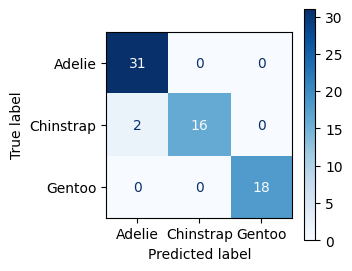

In [ ]:
#confusion matrix on test data
fig, ax = plt.subplots(figsize=(3, 3))
Confusion?.from_?(y_true=?_?,y_pred=?_?,\
                                values_format="d",cmap="Blues",ax=?);

In [ ]:
#classification report on test data
print(classification_?(y_true=?_?, y_pred=?_?))

              precision    recall  f1-score   support

      Adelie       0.94      1.00      0.97        31
   Chinstrap       1.00      0.89      0.94        18
      Gentoo       1.00      1.00      1.00        18

    accuracy                           0.97        67
   macro avg       0.98      0.96      0.97        67
weighted avg       0.97      0.97      0.97        67

